In [6]:
from typing import TypedDict

In [7]:
# 1.状态 State
class AgentState(TypedDict):
    message: str

In [8]:
# 2.创建 hello world 节点
def hello_world(state: AgentState) -> AgentState:
    """
    hello world 节点，修改一下状态
    :param state:修改前的状态
    :return:修改后的状态
    """
    state['message'] = 'hello world,' + state['message']
    return state

In [9]:
# 3.创建图
from langgraph.graph import StateGraph, START, END
builder = StateGraph(AgentState)

builder.add_node("hello_world", hello_world)

builder.add_edge(START, "hello_world")
builder.add_edge("hello_world", END)

# 编译图
graph = builder.compile()

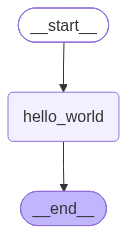

In [10]:
from IPython.display import Image, display
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [11]:
# 4.使用图
result = graph.invoke({
    "message": "maker"
})
print(result["message"])

hello world,maker
